In [1]:

import os
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from liftover import get_lifter
sns.set_context("talk", font_scale=1.35)

In [11]:
for chr in list(range(1,23)):
    if(chr==1):
        df=pd.read_table(f'/data2/processed/QTL_calling/rna/L2_manual/cM/cM.cis_qtl_egene.{chr}.txt')
    else:
        cur_df=pd.read_table(f'/data2/processed/QTL_calling/rna/L2_manual/cM/cM.cis_qtl_egene.{chr}.txt')
        df=pd.concat([df,cur_df])
    

In [12]:
df

,phenotype_id,num_var,beta_shape1,beta_shape2,true_df,pval_true_df,variant_id,start_distance,end_distance,ma_samples,ma_count,af,pval_nominal,slope,slope_se,pval_perm,pval_beta,qval,pval_nominal_threshold
0,ENSG00000238009,573,1.032587,63.914875,246.52669,0.002061,rs3845291,902843,890052,213,299,0.531348,0.000674,-0.257971,0.075086,0.115288,0.113909,0.396467,0.000091
1,ENSG00000241860,646,1.023588,73.718480,247.87627,0.003852,rs4379629,1013627,989472,208,274,0.429467,0.001473,0.254565,0.079313,0.240376,0.237608,0.537835,0.000075
2,ENSG00000241599,620,1.017523,71.818050,250.33891,0.027118,rs66868065,960522,960522,101,124,0.194357,0.015542,-0.206147,0.084716,0.854415,0.857231,0.806345,0.000074
3,ENSG00000229905,1232,1.053122,134.892100,249.84926,0.003328,rs4970461,156673,156673,129,151,0.763323,0.001294,-0.242127,0.074544,0.336966,0.337127,0.600356,0.000048
4,ENSG00000237491,1282,1.047713,139.076690,250.93674,0.000597,rs57181708,95738,70562,198,233,0.365204,0.000174,0.273649,0.071973,0.066793,0.069231,0.314005,0.000045
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
640,ENSG00000205559,2460,1.059887,241.666670,247.95644,0.000730,rs117323981,-9612,-11046,72,81,0.126959,0.000202,0.375677,0.099844,0.142686,0.141709,0.328777,0.000057
641,ENSG00000008735,2435,1.017015,272.445340,257.19043,0.003585,rs4838866,-353714,-353714,74,82,0.871473,0.001655,-0.309610,0.097520,0.615938,0.616728,0.527878,0.000041
642,ENSG00000100299,2396,1.051902,257.023800,253.26889,0.000111,rs6151419,-1665,-1686,73,77,0.120690,0.000026,-0.451687,0.105661,0.018998,0.022765,0.100067,0.000052
643,ENSG00000251322,2322,1.036897,235.414110,248.50658,0.001009,rs78721569,-708388,-763318,89,99,0.155172,0.000302,0.231835,0.063412,0.201380,0.197010,0.378840,0.000053


In [14]:
df['logp']=-np.log10(df['pval_nominal'])

Text(0.5, 1.0, 'eQTL Distance to TSS')

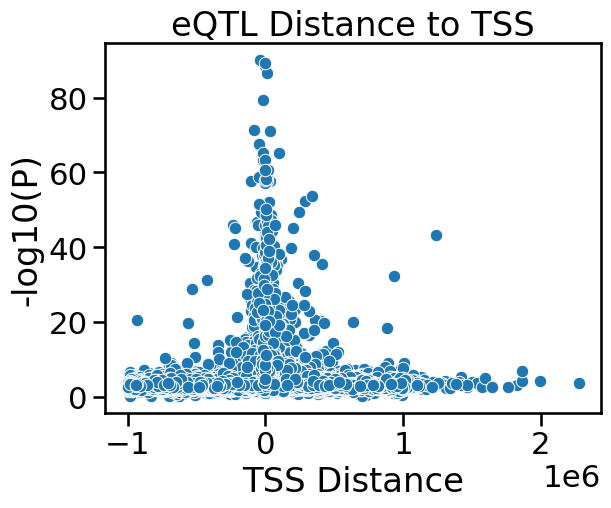

In [19]:
sns.scatterplot(data=df, x='start_distance',y='logp')
plt.xlabel('TSS Distance')
plt.ylabel('-log10(P)')
plt.title('eQTL Distance to TSS')

In [16]:
for chr in list(range(1,23)):
    if(chr==1):
        df_atac=pd.read_table(f'/data2/processed/QTL_calling/atac/permissive/L2_manual/cM/cM.cis_qtl_egene.{chr}.txt')
    else:
        cur_df=pd.read_table(f'/data2/processed/QTL_calling/atac/permissive/L2_manual/cM/cM.cis_qtl_egene.{chr}.txt')
        df_atac=pd.concat([df_atac,cur_df])

In [17]:
df_atac['logp']=-np.log10(df_atac['pval_nominal'])

Text(0.5, 1.0, 'caQTL Distance to Peak')

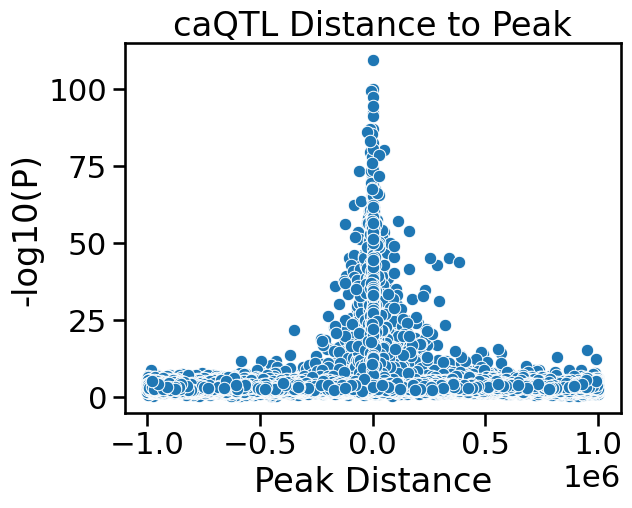

In [20]:
sns.scatterplot(data=df_atac, x='start_distance',y='logp')
plt.xlabel('Peak Distance')
plt.ylabel('-log10(P)')
plt.title('caQTL Distance to Peak')